# How Polymarket's 5-minute BTC market follows Binance, and who makes money

*The code was written by an AI assistant (Claude) from my instructions; see [How this was made](../README.md#how-this-was-made).*

**Data period:** 21 March to 5 April 2026 (UTC), 15.7 days of markets from my live capture. The lookup table used as a fair price is built in notebook 05 from Binance trades of September 2025 to February 2026.

Two questions about the same capture (21 March to 5 April 2026):

1. **How does Polymarket's price follow Binance?** Not only after big, isolated jumps: after any Binance move that
   should change the fair price, and over all moments with no threshold at all.
2. **Who makes money in this market?** Every Polymarket trade has a price, a size and a taker side, and every market
   has an outcome, so each trade can be valued at settlement and split between the taker, the maker and the fee.
   That shows whether fast takers win, whether makers lose to them and win it back from other takers, and who pays.

**Data** (my capture, one clock on a server in Ireland): Polymarket's best bid and ask for the Up token, saved every
100 ms; Polymarket's trade messages for the Up and Down tokens; every Binance BTCUSDT trade; each market's outcome as
Polymarket's price API reported it (`windows.csv`); the lookup table from notebook 05 (`clifford/clifford_grid.npz`),
used as a fair price.

**What is assumed** is listed at the end, separately from what is measured.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

BASE         = Path('data')     # folder with clob_bbo/, clob_trades/, binance_spot/ and windows.csv (or server_data/ holding them)
RESULTS      = Path('results'); RESULTS.mkdir(exist_ok=True)
FIGURES      = Path('../figures'); FIGURES.mkdir(exist_ok=True)
DATE_FROM    = None             # e.g. '2026-03-21' (UTC, inclusive); None = all the data
DATE_TO      = None

STEP_MS      = 100              # one clock for both venues
QUOTE_AGE_MS = 200              # a saved quote older than this is not used (the book is saved every 100 ms)
BN_AGE_MS    = 2000             # Binance can be quiet for a second or two; a longer gap is a feed problem
MOVE_C       = 3.0              # event: Binance moves the fair price by at least this many cents within 1 s
COOLDOWN_S   = 5.0              # minimum gap between events
MIN_TREM_S   = 6.0              # events need at least this much time left in their market
MID_BAND     = (0.05, 0.95)     # leave out prices pinned near 0 or 1
DELAYS_MS    = [0, 100, 200, 300, 400, 500, 700, 1000, 1500, 2000, 3000]
LAG_STEPS    = (-10, 50)        # section 2b: from 1 s before to 5 s after, in 100 ms steps
FEE_CHANGE_UTC = '2026-03-30'   # first day of Polymarket's new taker fee on crypto markets
REBATE_SHARE = 0.20             # ASSUMPTION: share of taker fees paid back to makers
N_BOOT       = 1000
SEED         = 7

## 1. Data

All feeds are put on one 100 ms clock. Book rows that cannot be real quotes of the current market are dropped
first: rows from the previous market's token (the recorder switches token a moment after each market opens), crossed
or locked books, and rows with one side empty. Trades are checked against the saved quotes, which also tells which
side the trade message reports.

In [2]:
t_from = pd.Timestamp(DATE_FROM, tz='UTC').value // 10**6 if DATE_FROM else 0
t_to   = (pd.Timestamp(DATE_TO, tz='UTC') + pd.Timedelta(days=1)).value // 10**6 if DATE_TO else 2**62

def find_feed(base, name):
    for c in [base / 'server_data' / name, base / name, base / 'data' / name]:
        if c.exists():
            return c
    found = sorted(str(p.parent) for p in Path(base).glob(f'**/{name}'))
    raise FileNotFoundError(f"Cannot find '{name}' under {base}. Folders that contain it: {found or 'none'}")

TOKEN_ID = {}
def token_codes(s):
    # Token ids are 70+ digit strings: give each one a small integer instead (-1 = missing)
    c = s.astype('category')
    lut = np.array([TOKEN_ID.setdefault(k, len(TOKEN_ID)) for k in c.cat.categories], dtype=np.int64)
    codes = c.cat.codes.to_numpy()
    out = np.full(len(s), -1, np.int64)
    out[codes >= 0] = lut[codes[codes >= 0]]
    return out

def read_feed(folder, cols):
    # Every hourly file of one feed, numbers as numbers, sorted by my clock
    parts = []
    for f in sorted(folder.glob('*.csv*')):
        try:
            df = pd.read_csv(f, usecols=lambda c: c in cols, dtype={'asset_id': str, 'side': str}, on_bad_lines='skip')
        except Exception as e:
            print(f'  Skipped {f.name}: {e}'); continue
        for c in df.columns.difference(['asset_id', 'side']):
            df[c] = pd.to_numeric(df[c], errors='coerce')
        df = df.dropna(subset=['local_ms'])
        if len(df) and df['local_ms'].max() > 1e15:                    # microseconds -> ms
            df['local_ms'] = df['local_ms'] // 1000
        df = df[(df['local_ms'] >= t_from) & (df['local_ms'] < t_to)]
        if not len(df):
            continue
        if 'asset_id' in cols:
            df['tok'] = token_codes(df.pop('asset_id')) if 'asset_id' in df else -1
        if 'side' in df:
            df['side'] = np.where(df['side'] == 'BUY', 1, np.where(df['side'] == 'SELL', -1, 0)).astype(np.int8)
        parts.append(df)
    if not parts:
        raise ValueError(f'No rows in {folder} in the chosen dates')
    return pd.concat(parts, ignore_index=True).sort_values('local_ms', kind='stable').reset_index(drop=True)

def asof(times, values, t):
    # The last value at or before each t, and its age in ms
    i = np.searchsorted(times, t, side='right') - 1
    ok = i >= 0
    out = np.full(len(t), np.nan); age = np.full(len(t), np.inf)
    out[ok] = values[i[ok]]; age[ok] = t[ok] - times[i[ok]]
    return out, age

bbo = read_feed(find_feed(BASE, 'clob_bbo'), {'local_ms', 'server_ms', 'best_bid', 'best_ask', 'asset_id'})
bn  = read_feed(find_feed(BASE, 'binance_spot'), {'local_ms', 'exchange_ms', 'price'}).dropna(subset=['price'])
trd = read_feed(find_feed(BASE, 'clob_trades'), {'local_ms', 'server_ms', 'price', 'size', 'side', 'fee_bps', 'asset_id'}).dropna(subset=['price', 'size'])
win = pd.read_csv(find_feed(BASE, 'windows.csv'))
print(f'Book rows: {len(bbo):,}   Binance trades: {len(bn):,}   Polymarket trades: {len(trd):,}   Markets listed: {len(win):,}')
if 'exchange_ms' in bn:
    d = (bn['local_ms'] - bn['exchange_ms']).dropna()
    print(f'Binance trades reach my server a median {d.median():.0f} ms after their Binance timestamp '
          f'(95th percentile {d.quantile(0.95):.0f} ms)')
    del d

Book rows: 13,516,253   Binance trades: 54,658,892   Polymarket trades: 18,224,645   Markets listed: 4,698
Binance trades reach my server a median 105 ms after their Binance timestamp (95th percentile 121 ms)


In [3]:
# ── The book: keep only rows that can be real quotes of the current market ──
b_t, b_tok = bbo['local_ms'].to_numpy(np.int64), bbo['tok'].to_numpy()
b_bid, b_ask = bbo['best_bid'].to_numpy(float), bbo['best_ask'].to_numpy(float)
b_srv = bbo['server_ms'].to_numpy(float) if 'server_ms' in bbo else np.full(len(b_t), np.nan)   # Polymarket's time of the book state
del bbo
w5 = lambda t_ms: np.asarray(t_ms) // 300_000                  # which 5-minute market a time falls in

# The Up token of each market: the token the recorder followed in the middle 100 seconds of the market
sec = (b_t // 1000) % 300
m = (sec >= 100) & (sec < 200) & (b_tok >= 0)
v = pd.DataFrame({'w': w5(b_t[m]), 'tok': b_tok[m]}).groupby(['w', 'tok']).size().rename('n').reset_index()
v = v.sort_values(['w', 'n'], ascending=[True, False]).drop_duplicates('w')
UP_TOK = pd.Series(v['tok'].to_numpy(), index=v['w'].to_numpy())
def up_tok_at(t_ms):
    return pd.Series(w5(t_ms)).map(UP_TOK).fillna(-2).to_numpy(np.int64)

bad = np.zeros(len(b_t), bool)
for name, x in [("another market's token", b_tok != up_tok_at(b_t)), ('crossed (bid above ask)', b_bid > b_ask + 1e-9),
                ('locked (bid = ask)', np.abs(b_bid - b_ask) < 1e-9), ('one side empty', (b_bid < 0.01) | (b_ask > 0.99))]:
    print(f'  {name:<24} {x.mean():7.2%} of saved rows')
    bad |= x
keep = np.where(~bad)[0]
keep = keep[np.r_[True, np.diff(b_t[keep]) > 0]]
print(f'Book rows kept: {len(keep):,} of {len(b_t):,}')
b_t, b_bid, b_ask, b_srv = b_t[keep], b_bid[keep], b_ask[keep], b_srv[keep]
del b_tok, bad, keep

  another market's token     0.19% of saved rows
  crossed (bid above ask)    0.01% of saved rows
  locked (bid = ask)         0.02% of saved rows
  one side empty             7.39% of saved rows
Book rows kept: 12,511,097 of 13,516,253


In [4]:
# ── Markets, outcomes and one 100 ms clock ───────────────────────────
win = win[win['outcome'].isin(['UP', 'DOWN'])].drop_duplicates('window_ts')
up_of = dict(zip(win['window_ts'].astype(np.int64), (win['outcome'] == 'UP').astype(float)))
bn_t, bn_p = bn['local_ms'].to_numpy(np.int64), bn['price'].to_numpy(float)
bn_x = bn['exchange_ms'].to_numpy(float) if 'exchange_ms' in bn else np.full(len(bn_t), np.nan)   # Binance's own time
del bn
t_first, t_last = max(b_t[0], bn_t[0]), min(b_t[-1], bn_t[-1])
win_ts = np.unique(w5(b_t)) * 300
win_ts = win_ts[(win_ts * 1000 >= t_first) & ((win_ts + 300) * 1000 <= t_last) & np.isin(win_ts, list(up_of))]
M, N_PER = len(win_ts), 300_000 // STEP_MS
y_m = np.array([up_of[w] for w in win_ts])                      # 1 if the market settled Up

grid  = (win_ts[:, None] * 1000 + np.arange(0, 300_000, STEP_MS)[None, :]).ravel()
mkt   = np.repeat(np.arange(M), N_PER)                          # market of each grid point
t_rem = np.tile((300_000 - np.arange(0, 300_000, STEP_MS)) / 1000, M)
px, px_age = asof(bn_t, bn_p, grid)
bid, q_age = asof(b_t, b_bid, grid)
ask = asof(b_t, b_ask, grid)[0]
mid = (bid + ask) / 2
quote_ok = q_age <= QUOTE_AGE_MS
DAYS = M * 300 / 86_400
print(f'Markets with an outcome and both feeds: {M:,} ({DAYS:.1f} days of markets), '
      f'{pd.Timestamp(win_ts[0], unit="s")} to {pd.Timestamp(win_ts[-1] + 300, unit="s")} UTC')
print(f'Grid points with a quote at most {QUOTE_AGE_MS} ms old: {quote_ok.mean():.1%}')
del q_age

# ── Fees, and intervals from resampling whole markets ────────────────
FEE_CHANGE_MS = pd.Timestamp(FEE_CHANGE_UTC, tz='UTC').value // 10**6
def taker_fee(p, t_ms):
    # Taker fee per share at token price p, in dollars: Polymarket's crypto fee before and after the change
    p = np.asarray(p, float)
    return np.where(np.asarray(t_ms) < FEE_CHANGE_MS, 0.25 * p * (p * (1 - p)) ** 2, 0.07 * p * (1 - p))

_rng = np.random.default_rng(SEED)
BOOT_W = np.stack([np.bincount(_rng.integers(0, M, M), minlength=M) for _ in range(N_BOOT)]).astype(np.float64)
def boot_ratio(m, num, den):
    # sum(num) / sum(den) in every resample of the markets
    s = BOOT_W @ np.stack([np.bincount(m, weights=np.asarray(x, float), minlength=M) for x in (num, den)], axis=1)
    return s[:, 0] / s[:, 1]
def boot_sum(m, x):
    return BOOT_W @ np.bincount(m, weights=np.asarray(x, float), minlength=M)
def ci(draws):
    return np.nanpercentile(draws, 2.5), np.nanpercentile(draws, 97.5)

Markets with an outcome and both feeds: 4,511 (15.7 days of markets), 2026-03-21 01:30:00 to 2026-04-05 18:55:00 UTC
Grid points with a quote at most 200 ms old: 92.6%


In [5]:
# ── A fair price from Binance: the lookup table from notebook 05 ─────
def find_grid_file(base):
    for c in [base.parent / 'clifford', base / 'clifford', base / 'data' / 'clifford']:
        if (c / 'clifford_grid.npz').exists():
            return c / 'clifford_grid.npz'
    raise FileNotFoundError(f'Cannot find clifford/clifford_grid.npz next to or inside {base} (written by notebook 05)')

_g = np.load(find_grid_file(BASE))
CDF = _g['cdf_grid'].astype(np.float64)
TREM_EDGES, RV_EDGES, BPS_AXIS = _g['trem_edges'], _g['rv_edges'], _g['bps_axis']
BPS_STEP = BPS_AXIS[1] - BPS_AXIS[0]
RIGHT_EDGES = BPS_AXIS + BPS_STEP

def table_p_up(margin_bps, t_rem_s, rv):
    # Read exactly as in notebook 05: the share of moves above -margin, on the right edges of the 0.1 bp bins
    ti = np.clip(np.searchsorted(TREM_EDGES, t_rem_s, side='right') - 1, 0, len(TREM_EDGES) - 1)
    ri = np.clip(np.searchsorted(RV_EDGES, rv, side='right'), 0, CDF.shape[0] - 1)
    x = np.clip(-np.asarray(margin_bps, float), RIGHT_EDGES[0], RIGHT_EDGES[-1])
    k = np.minimum(((x - RIGHT_EDGES[0]) / BPS_STEP).astype(np.int64), len(RIGHT_EDGES) - 2)
    w = (x - RIGHT_EDGES[k]) / BPS_STEP
    below = CDF[ri, ti, k] * (1 - w) + CDF[ri, ti, k + 1] * w
    return np.clip(1.0 - below, 0.001, 0.999)

# 60 s volatility from 1 s Binance bars, as compute_rv in notebook 05
bar_s0 = bn_t[0] // 1000
bars = np.full(bn_t[-1] // 1000 - bar_s0 + 1, np.nan)
bars[bn_t // 1000 - bar_s0] = bn_p                               # last trade of each second
_f = np.where(~np.isnan(bars), np.arange(len(bars)), 0)
np.maximum.accumulate(_f, out=_f)
bars = bars[_f]
_cs = np.concatenate([[0.0], np.cumsum(np.diff(np.log(bars)) ** 2)])
rv_bar = np.full(len(bars), np.nan)
rv_bar[60:] = np.sqrt(_cs[60:] - _cs[:-60])                     # uses the 60 returns up to the close of second s
open_px = asof(bn_t, bn_p, win_ts * 1000)[0]                    # Binance price when each market opened
# The same Binance prices on Binance's own clock, for the check in section 5c
_o = np.argsort(bn_x, kind='stable'); _o = _o[np.isfinite(bn_x[_o])]
px_x = asof(bn_x[_o].astype(np.int64), bn_p[_o], grid)[0]
open_x = asof(bn_x[_o].astype(np.int64), bn_p[_o], win_ts * 1000)[0]
del _f, _cs, bars, bn_t, bn_p, bn_x, _o

sec = grid // 1000 - 1 - bar_s0                                 # the last full second before each grid point
rv = np.full(len(grid), np.nan)
ok = (sec >= 0) & (sec < len(rv_bar)); rv[ok] = rv_bar[sec[ok]]
margin = (px / open_px[mkt] - 1) * 1e4                          # Binance move since the market opened (bps)
has_f = (px_age <= BN_AGE_MS) & np.isfinite(rv) & np.isfinite(margin)
fair = np.full(len(grid), np.nan)
fair[has_f] = table_p_up(margin[has_f], t_rem[has_f], rv[has_f])
del sec, ok

def binance_change(k):
    # Change in the fair price caused by Binance's move over the last k steps, time left and volatility held fixed
    out = np.full(len(grid), np.nan)
    i = np.where(has_f)[0]; i = i[i >= k]
    i = i[(mkt[i - k] == mkt[i]) & has_f[i - k]]
    out[i] = table_p_up(margin[i], t_rem[i], rv[i]) - table_p_up(margin[i - k], t_rem[i], rv[i])
    return out

k1s = 1000 // STEP_MS
dF_step, dF_1s = binance_change(1), binance_change(k1s)
valid = has_f & quote_ok & (t_rem >= MIN_TREM_S) & (mid > MID_BAND[0]) & (mid < MID_BAND[1])
print(f'Grid points usable (fresh data, {MIN_TREM_S:.0f} s or more left, mid inside {MID_BAND}): {valid.mean():.1%}')
del margin, px_age

Grid points usable (fresh data, 6 s or more left, mid inside (0.05, 0.95)): 81.1%


In [6]:
# ── Polymarket's trades as one ledger, in Up terms ───────────────────
tr_t, tr_p, tr_q = trd['local_ms'].to_numpy(np.int64), trd['price'].to_numpy(float), trd['size'].to_numpy(float)
tr_side, tr_tok = trd['side'].to_numpy(np.int64), trd['tok'].to_numpy()
tr_srv = trd['server_ms'].to_numpy(float) if 'server_ms' in trd else np.full(len(tr_t), np.nan)
tr_fbps = trd['fee_bps'].to_numpy(float) if 'fee_bps' in trd else np.full(len(tr_t), np.nan)
del trd
is_up = tr_tok == up_tok_at(tr_t)
# The Down token of each market: the other token traded in the middle of the market
sec_tr = (tr_t // 1000) % 300
m = (sec_tr >= 10) & (sec_tr < 290) & (tr_tok >= 0) & ~is_up
v = pd.DataFrame({'w': w5(tr_t[m]), 'tok': tr_tok[m]}).groupby(['w', 'tok']).size().rename('n').reset_index()
v = v.sort_values(['w', 'n'], ascending=[True, False]).drop_duplicates('w')
DOWN_TOK = pd.Series(v['tok'].to_numpy(), index=v['w'].to_numpy())
is_dn = tr_tok == pd.Series(w5(tr_t)).map(DOWN_TOK).fillna(-2).to_numpy(np.int64)

# Is 'side' the taker's side? A taker's buy prints at the ask, a sell at the bid
qb, qage = asof(b_t, b_bid, tr_t); qa = asof(b_t, b_ask, tr_t)[0]
u = is_up & (qage <= QUOTE_AGE_MS)
at_ask, at_bid = tr_p >= qa - 0.005, tr_p <= qb + 0.005
print(f'Up-token trades against the saved quote: buys at or above the ask {at_ask[u & (tr_side > 0)].mean():.1%} '
      f'(at or below the bid {at_bid[u & (tr_side > 0)].mean():.1%}); sells at or below the bid '
      f'{at_bid[u & (tr_side < 0)].mean():.1%} (at or above the ask {at_ask[u & (tr_side < 0)].mean():.1%})')
SIDE_SIGN = 1 if at_ask[u & (tr_side > 0)].mean() >= at_bid[u & (tr_side > 0)].mean() else -1
print(f"So 'side' is read as the {'taker' if SIDE_SIGN > 0 else 'maker'}'s side")

# A match printed on both tokens is counted once: drop Down prints with the same server time, size and Up price as an Up print
key = pd.DataFrame({'s': tr_srv, 'z': np.round(tr_q, 4), 'p': np.round(np.where(is_up, tr_p, 1 - tr_p), 4)})
dn = np.where(is_dn & np.isfinite(tr_srv))[0]
dup = np.zeros(len(tr_t), bool)
dup[dn] = key.iloc[dn].merge(key[is_up & np.isfinite(tr_srv)].drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').to_numpy()
print(f'Down-token prints that repeat an Up print, dropped: {dup.sum():,} of {is_dn.sum():,}')
if np.isfinite(tr_srv).any():
    dd = (tr_t - tr_srv)[np.isfinite(tr_srv)]
    print(f'Polymarket trade messages reach my server a median {np.median(dd):.0f} ms after their Polymarket timestamp '
          f'(5th percentile {np.percentile(dd, 5):.0f} ms, 95th {np.percentile(dd, 95):.0f} ms)')
    del dd
del key, dn

# Keep trades on the market's two tokens, inside one of the markets analysed
mi = np.searchsorted(win_ts, w5(tr_t) * 300)
inm = (mi < M) & (win_ts[np.minimum(mi, M - 1)] == w5(tr_t) * 300)
keep = (is_up | is_dn) & ~dup & inm & (tr_side != 0) & (tr_q > 0) & (tr_p > 0) & (tr_p < 1)
lt, lm, lq, ltok_p, lfbps = tr_t[keep], mi[keep], tr_q[keep], tr_p[keep], tr_fbps[keep]
lp_up = np.where(is_up[keep], ltok_p, 1 - ltok_p)                 # price in Up terms
ls = np.where(is_up[keep], tr_side[keep], -tr_side[keep]) * SIDE_SIGN   # +1: the taker bought Up or sold Down
lpaid = np.where(ls > 0, lp_up, 1 - lp_up)                       # what the taker paid for the side they took
lfee = taker_fee(ltok_p, lt)                                    # ASSUMPTION: fee on the price of the token traded
ly = y_m[lm]
lgain = ls * (ly - lp_up)                                       # taker's gain per share at settlement, before the fee
ltaker = lgain - lfee
lgrid = lm * N_PER + (lt - win_ts[lm] * 1000) // STEP_MS        # grid point at or before each trade
print(f'Trades on the two tokens of the markets analysed: {keep.sum():,} of {len(tr_t):,} '
      f'({is_up[keep].mean():.0%} on the Up token); {lq.sum() / 1e6:,.1f} million shares, '
      f'${(lq * ltok_p).sum() / 1e6:,.1f} million traded')
del tr_t, tr_p, tr_q, tr_side, tr_tok, tr_srv, tr_fbps, is_up, is_dn, dup, qb, qa, qage, at_ask, at_bid, u, mi, inm, keep, sec_tr

Up-token trades against the saved quote: buys at or above the ask 91.5% (at or below the bid 3.8%); sells at or below the bid 92.3% (at or above the ask 3.5%)
So 'side' is read as the taker's side
Down-token prints that repeat an Up print, dropped: 475 of 8,984,662
Polymarket trade messages reach my server a median 11 ms after their Polymarket timestamp (5th percentile 9 ms, 95th 37 ms)
Trades on the two tokens of the markets analysed: 18,075,183 of 18,224,645 (51% on the Up token); 546.2 million shares, $284.2 million traded


## 2. How Polymarket follows Binance

### 2a. After any Binance move that should move the price

An **event** is a moment when Binance's last-second move changes the fair price by at least `MOVE_C` cents (the
table from notebook 05, with time left and volatility held fixed). No calm period is required, so this covers moves
in the middle of trends too, and a $15 move counts more late in the market than early, as it should. Events are at
least `COOLDOWN_S` apart.

For each event the fair price, the mid, the **hit side** (the ask after a rise, the bid after a fall: the side a
taker would take) and the **other side** are followed from 2 s before to 5 s after, as changes since 2 s before the
event, in the direction of the move. Counting from 2 s before keeps the start outside the second in which the event
was picked; counting from inside it makes a lagging price look as if it never fully catches up (found on simulated
data).
*Share in the price* is the mid's move divided by the fair price's move at the same moment. *Hit minus other* is
positive if the side takers hit moves first, which is what takers taking out the stale quotes would do. The
**placebo** is the same at random moments with a random direction.

Events: 64,567 in 4,509 markets (171.8 an hour); fair-price move in the second before: median 4.4 c
Events with fresh quotes and a fair price over the whole path, used in the table and figure: 53,126 (82%)

Moves since 2 s before the event, in the direction of the move (cents)
 seconds_after_event  fair_move_c  mid_move_c  share_in_price    lo    hi  hit_minus_other_c  d_lo  d_hi  placebo_mid_c
                 0.0        5.566       1.624           0.292 0.286 0.298              0.067 0.055 0.078          0.004
                 0.2        6.412       2.246           0.350 0.344 0.357              0.190 0.176 0.202          0.003
                 0.5        6.730       4.106           0.610 0.602 0.619              0.527 0.509 0.545          0.007
                 1.0        6.946       5.736           0.826 0.817 0.835              0.341 0.326 0.357          0.014
                 2.0        7.355       6.533           0.888 0.880 0.897              0.147 0.134 0.160          0.022
  

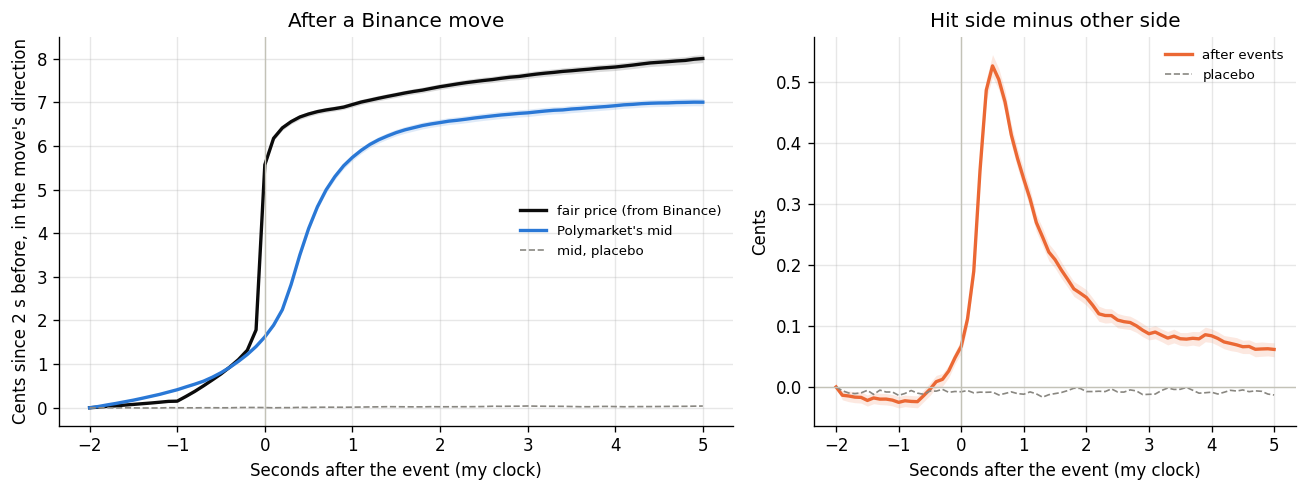

In [7]:
cand = np.where(valid & (np.abs(dF_1s) >= MOVE_C / 100))[0]
events, last = [], -np.inf
for i in cand:
    if grid[i] - last >= COOLDOWN_S * 1000:
        events.append(i); last = grid[i]
events = np.array(events, dtype=np.int64)
d_ev = np.sign(dF_1s[events])
mk_ev = mkt[events]
print(f'Events: {len(events):,} in {len(np.unique(mk_ev)):,} markets ({len(events) / (M * 300 / 3600):.1f} an hour); '
      f'fair-price move in the second before: median {np.median(np.abs(dF_1s[events])) * 100:.1f} c')

OFF = np.arange(-2 * k1s, 5 * k1s + 1)                          # -2 s to +5 s
I0 = int(np.where(OFF == 0)[0][0])
def paths(idx, d):
    # Changes in cents since 2 s before idx, in the direction d, for the fair price, mid and both sides
    j = idx[:, None] + OFF[None, :]
    ok = (j >= 0) & (j < len(grid))
    j = np.clip(j, 0, len(grid) - 1)
    b0 = np.clip(idx - 2 * k1s, 0, len(grid) - 1)
    ok &= (mkt[j] == mkt[idx][:, None]) & (mkt[b0] == mkt[idx])[:, None] & quote_ok[j] & quote_ok[b0][:, None]
    hit, hit0 = np.where(d[:, None] > 0, ask[j], bid[j]), np.where(d > 0, ask[b0], bid[b0])
    oth, oth0 = np.where(d[:, None] > 0, bid[j], ask[j]), np.where(d > 0, bid[b0], ask[b0])
    sg = d[:, None] * 100
    out = {'fair price': (fair[j] - fair[b0][:, None]) * sg, 'mid': (mid[j] - mid[b0][:, None]) * sg,
           'hit side': (hit - hit0[:, None]) * sg, 'other side': (oth - oth0[:, None]) * sg}
    return {k: np.where(ok & np.isfinite(x), x, np.nan) for k, x in out.items()}

def complete(paths_):
    # Keep only the paths with every value from -2 s to +5 s, so each point of a curve averages the same events
    ok = np.all([np.isfinite(v).all(1) for v in paths_.values()], axis=0)
    return {k: v[ok] for k, v in paths_.items()}, ok

P, full = complete(paths(events, d_ev))
mk_full = mk_ev[full]
print(f'Events with fresh quotes and a fair price over the whole path, used in the table and figure: {full.sum():,} ({full.mean():.0%})')
rng2 = np.random.default_rng(SEED + 1)
pool = np.where(valid & np.isfinite(dF_1s))[0]
pk = rng2.choice(pool, size=min(len(pool), len(events)), replace=False)
PL = complete(paths(pk, rng2.choice([-1.0, 1.0], size=len(pk))))[0]

rows = []
for s in [0, 0.2, 0.5, 1, 2, 5]:
    c = I0 + int(round(s * k1s))
    f, mm, h, o = (P[k][:, c] for k in ('fair price', 'mid', 'hit side', 'other side'))
    lo, hi = ci(boot_ratio(mk_full, mm, f))
    dlo, dhi = ci(boot_ratio(mk_full, h - o, np.ones(len(h))))
    rows.append({'seconds_after_event': s, 'fair_move_c': f.mean(), 'mid_move_c': mm.mean(),
                 'share_in_price': mm.sum() / f.sum(), 'lo': lo, 'hi': hi,
                 'hit_minus_other_c': (h - o).mean(), 'd_lo': dlo, 'd_hi': dhi,
                 'placebo_mid_c': PL['mid'][:, c].mean()})
absorb = pd.DataFrame(rows)
absorb.to_csv(RESULTS / 'polymarket_follows_binance_events.csv', index=False)
print('\nMoves since 2 s before the event, in the direction of the move (cents)')
print(absorb.round(3).to_string(index=False))

def band(v, m):
    # 95% interval of the average path, resampling markets
    sums = np.stack([np.bincount(m, weights=v[:, c], minlength=M) for c in range(v.shape[1])], axis=1)
    d = (BOOT_W @ sums) / (BOOT_W @ np.bincount(m, minlength=M).astype(float))[:, None]
    return np.percentile(d, 2.5, 0), np.percentile(d, 97.5, 0)

tsec = OFF * STEP_MS / 1000
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1.4, 1]})
for k, col, lab in [('fair price', '#0b0b0b', 'fair price (from Binance)'), ('mid', '#2a78d6', "Polymarket's mid")]:
    a1.plot(tsec, P[k].mean(0), color=col, lw=2, label=lab)
    a1.fill_between(tsec, *band(P[k], mk_full), color=col, alpha=0.15, lw=0)
a1.plot(tsec, PL['mid'].mean(0), color='#898781', ls='--', lw=1, label='mid, placebo')
a1.set_ylabel("Cents since 2 s before, in the move's direction")
a1.set_title('After a Binance move'); a1.legend(fontsize=8, frameon=False)
a2.plot(tsec, (P['hit side'] - P['other side']).mean(0), color='#eb6834', lw=2, label='after events')
a2.fill_between(tsec, *band(P['hit side'] - P['other side'], mk_full), color='#eb6834', alpha=0.15, lw=0)
a2.plot(tsec, (PL['hit side'] - PL['other side']).mean(0), color='#898781', ls='--', lw=1, label='placebo')
a2.axhline(0, color='#c3c2b7', lw=0.8)
a2.set_ylabel('Cents'); a2.set_title('Hit side minus other side'); a2.legend(fontsize=8, frameon=False)
for a in (a1, a2):
    a.axvline(0, color='#c3c2b7', lw=0.8); a.set_xlabel('Seconds after the event (my clock)')
plt.tight_layout(); plt.savefig(FIGURES / '01_event_paths.png', dpi=150); plt.show()

### 2b. All moments, no threshold

Every 100 ms change in Polymarket's mid is regressed on the Binance-driven changes in the fair price over the 5 s
before it and the 1 s after it (a distributed-lag regression; the lags after it test whether Polymarket ever moves
first). The cumulative coefficient at lag *k* is how much of a one-cent change in the fair price has reached the mid
*k* ms later. It levels off below 1 because the table's fair price is only an estimate and Polymarket's traders do
not use it, so the curve is also shown as a share of where it is after 5 s. Intervals come from resampling markets.

Times are on my clock. My server sees a Binance trade a median 105 ms after Binance's timestamp and a Polymarket trade
message a median 11 ms after Polymarket's (section 1). Section 5c repeats this on the exchanges' own clocks.

Steps used: 10,917,152 of 13,533,000
 lag_ms  cumulative    lo    hi  share_of_5s_response  share_lo  share_hi
  -1000       0.005 0.004 0.006                 0.007     0.005     0.008
   -100       0.079 0.075 0.082                 0.106     0.102     0.111
      0       0.097 0.093 0.101                 0.131     0.126     0.136
    100       0.124 0.119 0.128                 0.167     0.161     0.172
    200       0.161 0.156 0.166                 0.218     0.212     0.224
    300       0.240 0.233 0.246                 0.324     0.316     0.332
    500       0.420 0.411 0.429                 0.567     0.557     0.578
    700       0.535 0.525 0.546                 0.723     0.713     0.734
   1000       0.629 0.619 0.640                 0.850     0.840     0.860
   1500       0.695 0.685 0.707                 0.940     0.930     0.949
   2000       0.719 0.708 0.730                 0.972     0.963     0.981
   3000       0.733 0.722 0.744                 0.991     0.983     0.999
 

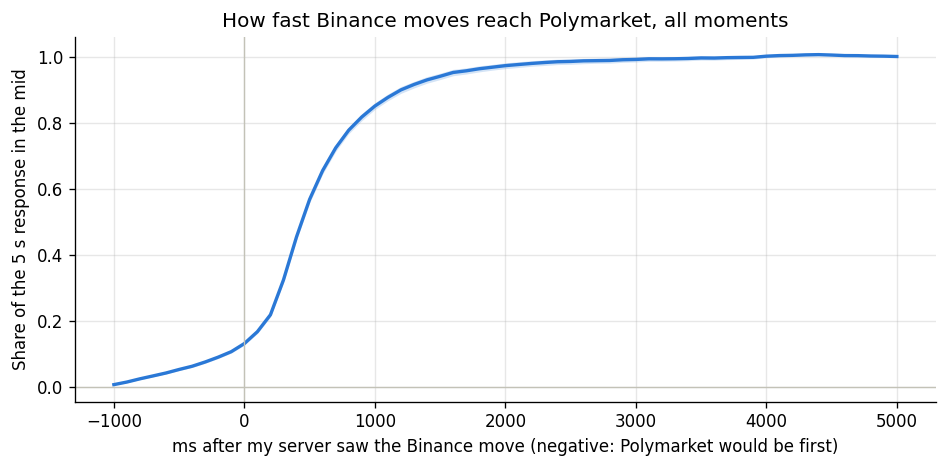

In [8]:
okstep = valid & np.r_[False, valid[:-1] & (mkt[1:] == mkt[:-1])] & np.isfinite(dF_step)
dF = np.where(okstep, dF_step, 0.0)
dM = np.where(okstep, np.diff(mid, prepend=np.nan), 0.0)
K = np.arange(LAG_STEPS[0], LAG_STEPS[1] + 1)                   # lag of the Binance change in steps (negative: after)
J = np.arange(0, K[-1] - K[0] + 1)

def lagged(a, b, k):
    # Per-market sums of a[t] * b[t - k], using pairs inside one market only
    n = len(a)
    if k >= 0:
        x, y, m0, m1 = a[k:], b[:n - k], mkt[k:], mkt[:n - k]
    else:
        x, y, m0, m1 = a[:n + k], b[-k:], mkt[:n + k], mkt[-k:]
    same = m0 == m1
    return np.bincount(m0[same], weights=(x * y)[same], minlength=M)

XY = np.stack([lagged(dM, dF, k) for k in K], axis=1)
XX = np.stack([lagged(dF, dF, j) for j in J], axis=1)
def response(xy, xx):
    # Cumulative distributed-lag response of the mid to a unit Binance-driven change in the fair price
    return np.cumsum(np.linalg.solve(xx[np.abs(K[:, None] - K[None, :])], xy))
cum = response(XY.sum(0), XX.sum(0))
draws = np.array([response(BOOT_W[b] @ XY, BOOT_W[b] @ XX) for b in range(N_BOOT)])
share, share_d = cum / cum[-1], draws / draws[:, [-1]]

rows = []
for k in [-10, -1, 0, 1, 2, 3, 5, 7, 10, 15, 20, 30, 50]:
    if K[0] <= k <= K[-1]:
        c = int(np.where(K == k)[0][0])
        lo, hi = ci(draws[:, c]); slo, shi = ci(share_d[:, c])
        rows.append({'lag_ms': k * STEP_MS, 'cumulative': cum[c], 'lo': lo, 'hi': hi,
                     'share_of_5s_response': share[c], 'share_lo': slo, 'share_hi': shi})
lagtab = pd.DataFrame(rows)
lagtab.to_csv(RESULTS / 'polymarket_follows_binance_all_moments.csv', index=False)
print(f'Steps used: {okstep.sum():,} of {len(grid):,}')
print(lagtab.round(3).to_string(index=False))

def reach(sh, q):
    # First lag at which the share reaches q (negative: before my server saw the Binance move)
    return K[np.argmax(sh >= q)] * STEP_MS if (sh >= q).any() else np.nan
for q in [0.5, 0.9]:
    lo, hi = ci(np.array([reach(s, q) for s in share_d]))
    print(f'{q:.0%} of the 5 s response is in the mid at {reach(share, q):.0f} ms (95% interval {lo:.0f} to {hi:.0f})')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(K * STEP_MS, share, color='#2a78d6', lw=2)
ax.fill_between(K * STEP_MS, np.nanpercentile(share_d, 2.5, 0), np.nanpercentile(share_d, 97.5, 0), color='#2a78d6', alpha=0.2, lw=0)
ax.axvline(0, color='#c3c2b7', lw=0.8); ax.axhline(0, color='#c3c2b7', lw=0.8)
ax.set_xlabel('ms after my server saw the Binance move (negative: Polymarket would be first)')
ax.set_ylabel('Share of the 5 s response in the mid')
ax.set_title('How fast Binance moves reach Polymarket, all moments'); plt.tight_layout()
plt.savefig(FIGURES / '01_all_moments_response.png', dpi=150); plt.show()

## 3. What being fast is worth

**The strategy, on the saved quotes.** After each event of section 2a, buy the side the move points to at the price
shown `L` ms later (Up at the ask after a rise, Down at 1 − Up bid after a fall, which is the Down ask because the two
tokens trade in one matched book), pay the taker fee, and hold to settlement: a winning share pays $1. No mid is used.
This assumes every quote in the saved book is filled instantly at the price shown. It ignores the ~10 ms an order
needs to reach Polymarket, that a faster trader may take the quote first, and that a saved quote can be up to 100 ms
old, so it shows the latest moment at which the trade still pays, not a profit anyone could count on.
`L` is on my clock, which sees Binance trades about 105 ms after Binance.

**Real takers.** The same question with real fills: every trade in the ledger whose taker went the way of the move,
in the same market, by how long after the event it happened, valued at settlement. These are real prices, but the
traders may also be reacting to things that happened after the event.

Buying at the saved quote L ms after the event, held to settlement (cents per share, after the fee)
 delay_ms     n  paid_c  net_c    lo    hi  share_won_money
        0 64567   52.01   3.57  3.31  3.82             0.57
      100 64565   52.29   3.28  3.02  3.54             0.57
      200 64564   52.69   2.88  2.63  3.14             0.57
      300 64563   53.36   2.22  1.95  2.48             0.57
      400 64564   54.11   1.47  1.20  1.73             0.57
      500 64565   54.73   0.85  0.58  1.12             0.57
      700 64559   55.58  -0.01 -0.28  0.26             0.57
     1000 64562   56.24  -0.67 -0.95 -0.40             0.57
     1500 64558   56.74  -1.16 -1.44 -0.90             0.57
     2000 64558   56.93  -1.35 -1.63 -1.09             0.57
     3000 64552   57.11  -1.53 -1.81 -1.26             0.57
Profitable with 95% confidence at every delay up to 500 ms

Real takers who went the way of the move, by when they traded (cents per share after the fee, held to settlement)
    tr

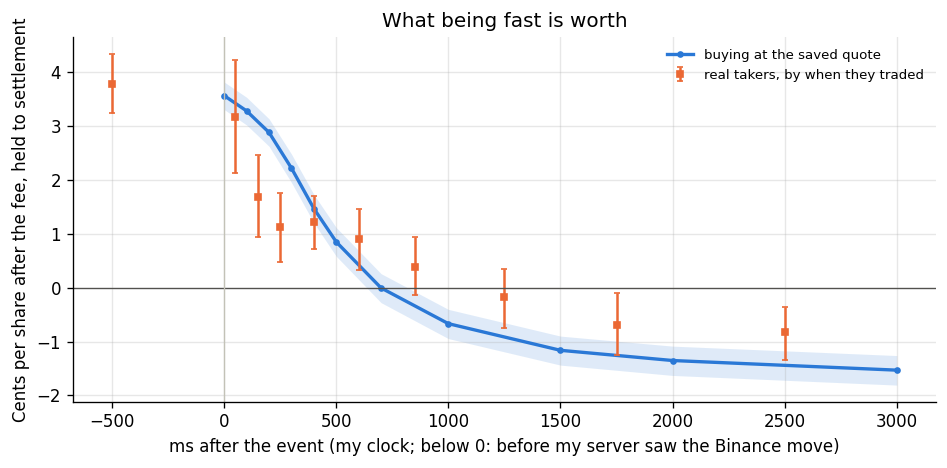

In [9]:
won_ev = np.where(d_ev > 0, y_m[mk_ev], 1 - y_m[mk_ev])
rows = []
for L in DELAYS_MS:
    j = events + L // STEP_MS
    ok = j < len(grid); j = np.minimum(j, len(grid) - 1)
    ok &= (mkt[j] == mk_ev) & quote_ok[j]
    paid = np.where(d_ev > 0, ask[j], 1 - bid[j])
    net = (won_ev - paid - taker_fee(paid, grid[j])) * 100
    lo, hi = ci(boot_ratio(mk_ev[ok], net[ok], np.ones(ok.sum())))
    rows.append({'delay_ms': L, 'n': int(ok.sum()), 'paid_c': paid[ok].mean() * 100, 'net_c': net[ok].mean(),
                 'lo': lo, 'hi': hi, 'share_won_money': (net[ok] > 0).mean()})
speed = pd.DataFrame(rows)
speed.to_csv(RESULTS / 'polymarket_taker_speed_settlement.csv', index=False)
print('Buying at the saved quote L ms after the event, held to settlement (cents per share, after the fee)')
print(speed.round(2).to_string(index=False))
run = np.cumprod(speed['lo'].to_numpy() > 0).astype(bool)         # every delay up to here has its whole interval above zero
print(f"Profitable with 95% confidence at every delay up to {speed['delay_ms'][run].max()} ms" if run.any()
      else 'At no delay is the whole 95% interval above zero')

DT_EDGES = [-1000, 0, 100, 200, 300, 500, 700, 1000, 1500, 2000, 3000]
def real_takers(starts, dirs):
    # Ledger trades in the same market from -1 s to +3 s whose taker went the way of the move, by time after the start
    t0 = grid[starts]
    lo_, hi_ = np.searchsorted(lt, t0 + DT_EDGES[0]), np.searchsorted(lt, t0 + DT_EDGES[-1])
    cnt = hi_ - lo_
    e = np.repeat(np.arange(len(starts)), cnt)
    k = np.repeat(lo_ - np.r_[0, np.cumsum(cnt)[:-1]], cnt) + np.arange(cnt.sum())
    ok = (lm[k] == mkt[starts[e]]) & (ls[k] == dirs[e])
    e, k = e[ok], k[ok]
    b = np.digitize(lt[k] - t0[e], DT_EDGES) - 1
    rows = []
    for i in range(len(DT_EDGES) - 1):
        s = b == i
        r = {'trade_ms': f'{DT_EDGES[i]} to {DT_EDGES[i + 1]}', 'trades': int(s.sum()),
             'starts_with_one': len(np.unique(e[s])) / len(starts)}
        if s.any():
            q, pnl = lq[k[s]], ltaker[k[s]] * 100
            lo, hi = ci(boot_ratio(lm[k[s]], pnl * q, q))
            r.update({'paid_c': lpaid[k[s]].mean() * 100, 'net_c_per_share': (pnl * q).sum() / q.sum(), 'lo': lo, 'hi': hi})
        rows.append(r)
    return pd.DataFrame(rows)

real = real_takers(events, d_ev)
real.to_csv(RESULTS / 'polymarket_real_takers_after_events.csv', index=False)
print('\nReal takers who went the way of the move, by when they traded (cents per share after the fee, held to settlement)')
print(real.round(2).to_string(index=False))
print('Same at random moments with a random direction:')
print(real_takers(pk, rng2.choice([-1.0, 1.0], size=len(pk)))[['trade_ms', 'trades', 'starts_with_one', 'net_c_per_share']]
      .round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(speed['delay_ms'], speed['net_c'], marker='o', ms=3, lw=2, color='#2a78d6', label='buying at the saved quote')
ax.fill_between(speed['delay_ms'], speed['lo'], speed['hi'], color='#2a78d6', alpha=0.15, lw=0)
r = real.dropna(subset=['net_c_per_share']).copy()
r['x'] = [np.mean([DT_EDGES[i], DT_EDGES[i + 1]]) for i in r.index]
ax.errorbar(r['x'], r['net_c_per_share'], yerr=[r['net_c_per_share'] - r['lo'], r['hi'] - r['net_c_per_share']],
            fmt='s', ms=4, color='#eb6834', capsize=2, label='real takers, by when they traded')
ax.axhline(0, color='#52514e', lw=0.8); ax.axvline(0, color='#c3c2b7', lw=0.8)
ax.set_xlabel('ms after the event (my clock; below 0: before my server saw the Binance move)')
ax.set_ylabel('Cents per share after the fee, held to settlement')
ax.set_title('What being fast is worth'); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(FIGURES / '01_speed_value.png', dpi=150); plt.show()

## 4. Who makes money

Every trade in the ledger, valued at settlement as if held: the taker gains `side × (outcome − price)` per share
and pays the fee; the maker gets the opposite of the taker's gain plus, by assumption, `REBATE_SHARE` of the fee;
Polymarket keeps the rest of the fee. The three always add up to zero.

If makers lose to fast takers, they have to win it back somewhere to keep quoting: from the spread paid by takers who
know nothing more than the price, from rebates, or from rewards. The ledger measures the first directly, as the
makers' result on each group of trades; rebates are an assumption and rewards are not included.

Takers are split by **how far Binance had moved the fair price their way in the second before the trade**: a taker who
buys Up right after Binance jumped up is trading on news that is not in the price yet. Takers with no Binance move
behind them are then split by the price they paid and by trade size.

Valued at settlement, 15.7 days of markets. Dollars are totals over the whole period.
                            takers   trades  share_of_shares  taker_c_per_share     lo     hi   takers_usd   makers_usd  makers_with_rebates_usd  polymarket_fees_usd
       Binance moved their way 2c+  2208347            0.120              1.546  1.282  1.797  1015937.964 -1563067.475             -1453641.573           437703.609
               their way 0.5 to 2c  1038430            0.061              0.143 -0.208  0.456    47712.177  -232826.450              -195803.595           148091.418
      no Binance move (under 0.5c) 12518345            0.701             -1.135 -1.230 -1.052 -4347568.108  2066952.636              2523075.730          1824492.378
                against them 0.5c+  1683757            0.082             -4.043 -4.405 -3.665 -1817499.103  1500042.949              1563534.179           253964.923
no fair price (first second, gaps)   626304            0.035             -1.017 -1.3

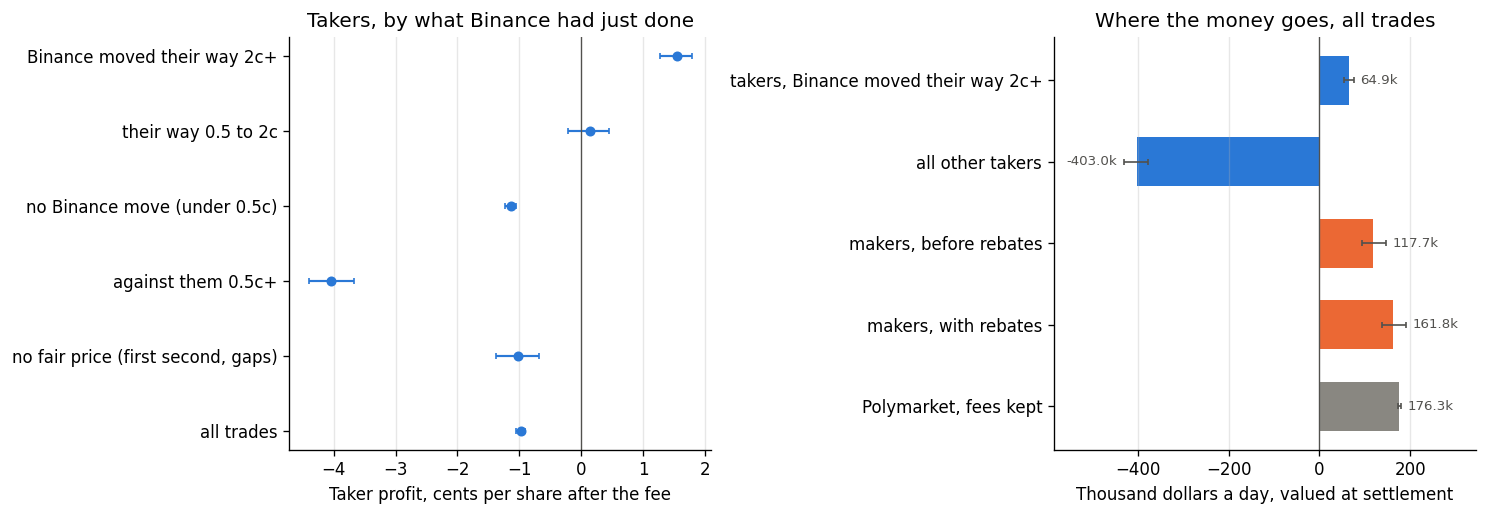

In [10]:
# Cents the fair price moved the taker's way in the second before the trade. My Binance feed arrives about 105 ms late,
# so the grid point just after the trade is Binance as it was when the trade happened (checked on simulated data)
x = ls * dF_1s[np.minimum(lgrid + 1, len(grid) - 1)] * 100
lmaker, lreb = -lgain, REBATE_SHARE * lfee
GROUPS = [('Binance moved their way 2c+', x >= 2),
          ('their way 0.5 to 2c', (x >= 0.5) & (x < 2)),
          ('no Binance move (under 0.5c)', np.abs(x) < 0.5),
          ('against them 0.5c+', x <= -0.5),
          ('no fair price (first second, gaps)', ~np.isfinite(x))]

def ledger_row(name, s):
    q, mm = lq[s], lm[s]
    lo, hi = ci(boot_ratio(mm, ltaker[s] * q, q) * 100)
    tot = lambda v: (v[s] * q).sum()
    return {'takers': name, 'trades': int(s.sum()), 'share_of_shares': q.sum() / lq.sum(),
            'taker_c_per_share': tot(ltaker) / q.sum() * 100, 'lo': lo, 'hi': hi,
            'takers_usd': tot(ltaker), 'makers_usd': tot(lmaker), 'makers_with_rebates_usd': tot(lmaker + lreb),
            'polymarket_fees_usd': tot(lfee - lreb)}

ALL = np.ones(len(lt), bool)
who = pd.DataFrame([ledger_row(n, s) for n, s in GROUPS] + [ledger_row('all trades', ALL)])
who.to_csv(RESULTS / 'polymarket_who_makes_money.csv', index=False)
pd.set_option('display.width', 200)
print(f'Valued at settlement, {DAYS:.1f} days of markets. Dollars are totals over the whole period.')
print(who.round(3).to_string(index=False))
print(f'Check: takers + makers with rebates + Polymarket = {who.iloc[-1][["takers_usd", "makers_with_rebates_usd", "polymarket_fees_usd"]].sum():.6f}')

for name, v in [('Takers', ltaker), ('Makers before rebates', lmaker), ('Makers with rebates', lmaker + lreb)]:
    lo, hi = ci(boot_sum(lm, v * lq))
    print(f'{name:<22} ${(v * lq).sum():>12,.0f}   (95% interval {lo:,.0f} to {hi:,.0f})   ${(v * lq).sum() / DAYS:,.0f} a day')

per = pd.Categorical.from_codes(np.where(lt < FEE_CHANGE_MS, 0, np.where(lt >= FEE_CHANGE_MS + 86_400_000, 2, 1)).astype(np.int8),
                                ['before the fee change', 'change day', 'after'])   # one byte a trade, not a string
print('\nBy period (30 March, the day the fee changed, left out):')
print(pd.DataFrame([ledger_row(p, per == p) for p in ['before the fee change', 'after']])
      [['takers', 'trades', 'taker_c_per_share', 'lo', 'hi', 'takers_usd', 'makers_usd', 'polymarket_fees_usd']].round(3).to_string(index=False))

calm = np.abs(x) < 0.5
paid_bins = [0, 0.1, 0.3, 0.7, 0.9, 1.0001]
size_bins = [0, 10, 100, np.inf]
rows = [ledger_row(f'paid {a:.1f} to {min(b, 1):.1f}', calm & (lpaid >= a) & (lpaid < b)) for a, b in zip(paid_bins[:-1], paid_bins[1:])]
rows += [ledger_row(f'{a:g} to {b:g} shares', calm & (lq > a) & (lq <= b)) for a, b in zip(size_bins[:-1], size_bins[1:])]
print('\nTakers with no Binance move behind them, by the price they paid and by trade size:')
print(pd.DataFrame(rows)[['takers', 'trades', 'share_of_shares', 'taker_c_per_share', 'lo', 'hi', 'takers_usd']].round(3).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={'width_ratios': [1, 1]})
g = who.iloc[::-1].reset_index(drop=True)
a1.errorbar(g['taker_c_per_share'], g.index, xerr=[g['taker_c_per_share'] - g['lo'], g['hi'] - g['taker_c_per_share']],
            fmt='o', ms=5, lw=1.3, capsize=2, color='#2a78d6')
a1.set_yticks(g.index); a1.set_yticklabels(g['takers']); a1.grid(axis='y', visible=False)
a1.axvline(0, color='#52514e', lw=0.8)
a1.set_xlabel('Taker profit, cents per share after the fee'); a1.set_title('Takers, by what Binance had just done')
fast = x >= 2
parts = {'takers, Binance moved their way 2c+': ltaker * lq * fast, 'all other takers': ltaker * lq * ~fast,
         'makers, before rebates': lmaker * lq, 'makers, with rebates': (lmaker + lreb) * lq,
         'Polymarket, fees kept': (lfee - lreb) * lq}
names = list(parts)[::-1]
tot = np.array([parts[n].sum() for n in names]) / DAYS / 1000
lohi = np.array([ci(boot_sum(lm, parts[n])) for n in names]) / DAYS / 1000
a2.barh(names, tot, height=0.6, color=['#898781', '#eb6834', '#eb6834', '#2a78d6', '#2a78d6'],
        xerr=[tot - lohi[:, 0], lohi[:, 1] - tot], error_kw={'ecolor': '#52514e', 'lw': 1, 'capsize': 2})
for i, v in enumerate(tot):
    end = lohi[i, 1] if v >= 0 else lohi[i, 0]
    a2.annotate(f'{v:,.1f}k', (end, i), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                ha='left' if v >= 0 else 'right', va='center', fontsize=8, color='#52514e')
a2.axvline(0, color='#52514e', lw=0.8); a2.margins(x=0.25); a2.grid(axis='y', visible=False)
a2.set_xlabel('Thousand dollars a day, valued at settlement'); a2.set_title('Where the money goes, all trades')
plt.tight_layout(); plt.savefig(FIGURES / '01_who_makes_money.png', dpi=150); plt.show()

## 5. Stress tests

Each check asks whether a result above could come from the data or from a choice in the code rather than from the
market. They use the same data and the same resampling of markets for the intervals.

**5a. The data.** Does each market's recorded outcome agree with where it traded in its last second, and with
Binance? Are trades recorded twice? Is the taker side right in every group of section 4, and what does the trade
message's own fee field show?

In [11]:
# ── 5a. Outcomes, repeated trades, taker side by group, fee field ────
t_in = lt - win_ts[lm] * 1000                                   # ms since the market opened
last = t_in >= 299_000
vol = np.bincount(lm[last], weights=lq[last], minlength=M)
vw = np.bincount(lm[last], weights=(lp_up * lq)[last], minlength=M) / np.where(vol > 0, vol, np.nan)
dec = (vol > 0) & ((vw > 0.9) | (vw < 0.1))
agree = (vw > 0.5) == (y_m > 0.5)
print(f'Markets that traded above 0.90 or below 0.10 in their last second: {dec.sum():,} of {M:,}. The recorded outcome '
      f'agrees with that price in {agree[dec].mean():.2%} of them ({(dec & ~agree).sum()} disagree)')
close = px[np.arange(M) * N_PER + N_PER - 1]
okb = np.isfinite(close) & np.isfinite(open_px)
print(f'The outcome agrees with Binance (last price above the open) in {((close > open_px) == (y_m > 0.5))[okb].mean():.1%} '
      f'of markets; the market settles on Chainlink, so tiny moves can differ')

same = pd.DataFrame({'t': lt, 'q': lq, 'p': lp_up, 's': ls}).duplicated(keep='first').to_numpy()
print(f'Trades identical to an earlier one in time (ms), size, price and side: {same.sum():,} ({lq[same].sum() / lq.sum():.2%} of shares). '
      f'Some are real (one order filled by two makers with the same size), so this is an upper bound on double recording')

# A taker's buy prints at the ask and a sell at the bid. The book moves fast after Binance moves, so a trade counts as
# matching if it matches the saved quote just before it or the one just after it (each at most 200 ms away)
ib = np.searchsorted(b_t, lt, side='right') - 1
ia = np.minimum(ib + 1, len(b_t) - 1); ib = np.maximum(ib, 0)
near_b = (b_t[ib] <= lt) & (lt - b_t[ib] <= QUOTE_AGE_MS)
near_a = (b_t[ia] > lt) & (b_t[ia] - lt <= QUOTE_AGE_MS)
match = lambda i: np.where(ls > 0, lp_up >= b_ask[i] - 0.005, lp_up <= b_bid[i] + 0.005)
fresh = near_b | near_a
side_ok = (near_b & match(ib)) | (near_a & match(ia))
print('\nShare of trades printed on the side their taker side says (against the saved quote just before or just after):')
print(pd.Series({n: side_ok[s & fresh].mean() for n, s in GROUPS + [('all trades', ALL)]}).map('{:.1%}'.format).to_string())
beyond = near_b & np.where(ls > 0, lp_up > b_ask[ib] + 0.005, lp_up < b_bid[ib] - 0.005)
print(f'Printed beyond the best quote just before them (took more than one price level): trades of 100+ shares '
      f'{beyond[near_b & (lq >= 100)].mean():.1%}, all trades {beyond[near_b].mean():.1%}')
del ib, ia, near_b, near_a, beyond, same

fee_tab = pd.DataFrame({'period': per, 'fee_bps': lfbps}).query("period != 'change day'")
print('\nThe trade message fee field (fee_bps), most common values by period:')
print(fee_tab.groupby('period', observed=True)['fee_bps'].value_counts(normalize=True, dropna=False).groupby(level=0).head(3)
      .map('{:.1%}'.format).to_string())
del fee_tab

Markets that traded above 0.90 or below 0.10 in their last second: 3,262 of 4,511. The recorded outcome agrees with that price in 99.94% of them (2 disagree)
The outcome agrees with Binance (last price above the open) in 96.9% of markets; the market settles on Chainlink, so tiny moves can differ
Trades identical to an earlier one in time (ms), size, price and side: 80,187 (0.20% of shares). Some are real (one order filled by two makers with the same size), so this is an upper bound on double recording

Share of trades printed on the side their taker side says (against the saved quote just before or just after):
Binance moved their way 2c+           90.6%
their way 0.5 to 2c                   93.2%
no Binance move (under 0.5c)          95.0%
against them 0.5c+                    93.1%
no fair price (first second, gaps)    94.8%
all trades                            94.2%
Printed beyond the best quote just before them (took more than one price level): trades of 100+ shares 28.8%, all tra

**5b. Who makes money, made hard to pass.** The split of section 4 is rerun with one thing changed at a time:
only trades whose print matches their taker side; Binance read at the grid point before the trade instead of after;
the raw Binance move in dollars instead of the table; a **placebo** that uses the Binance move from 60 s before the
trade, which should be in the price long before (so it should not separate winners from losers); without the largest
1% of trades; without the last 10 s of each market; only prices between 0.10 and 0.90; each trade valued at the mid
30 s later (or at settlement if the market ends first) instead of held to settlement; and each period of the fee.
Then the same numbers day by day.

In [12]:
# ── 5b. The split of section 4, one change at a time ─────────────────
def per_share(s, val):
    q = lq[s]
    lo, hi = ci(boot_ratio(lm[s], val[s] * q, q) * 100)
    return (val[s] * q).sum() / q.sum() * 100, lo, hi

def split_row(name, sig, sel, val=ltaker, gain=lgain, fast=2.0, none=0.5):
    f, n, a = sel & (sig >= fast), sel & (np.abs(sig) < none), sel & (sig <= -none)
    fv, nv, av = per_share(f, val), per_share(n, val), per_share(a, val)
    mk = boot_sum(lm[sel], -(gain * lq)[sel]) / DAYS / 1000
    return {'variant': name, 'fast_share': lq[f].sum() / lq[sel].sum(), 'fast_c': fv[0], 'fast_lo': fv[1], 'fast_hi': fv[2],
            'none_c': nv[0], 'none_lo': nv[1], 'none_hi': nv[2], 'against_c': av[0],
            'makers_k_day': (-(gain * lq)[sel]).sum() / DAYS / 1000, 'mk_lo': ci(mk)[0], 'mk_hi': ci(mk)[1]}

g1 = np.minimum(lgrid + 1, len(grid) - 1)
g0 = g1 - k1s
usd = np.where((g0 >= 0) & (mkt[np.maximum(g0, 0)] == lm), ls * (px[g1] - px[np.maximum(g0, 0)]), np.nan)
gp = g1 - 60 * k1s
x_60 = np.where((gp >= 0) & (mkt[np.maximum(gp, 0)] == lm), ls * dF_1s[np.maximum(gp, 0)] * 100, np.nan)
x_before = ls * dF_1s[lgrid] * 100

j30 = lgrid + 30_000 // STEP_MS
inside = j30 < (lm + 1) * N_PER
j30 = np.minimum(j30, len(grid) - 1)
later = np.where(inside, np.where(quote_ok[j30], mid[j30], np.nan), ly)   # mid 30 s later, or the outcome if the market ends first
g30 = ls * (later - lp_up)
ok30 = np.isfinite(g30)
g30 = np.nan_to_num(g30)
del g0, g1, gp, j30, inside, later

rows = [split_row('as in section 4', x, ALL),
        split_row('only trades printed on their taker side', x, fresh & side_ok),
        split_row('Binance read just before the trade', x_before, ALL),
        split_row('raw Binance move: $10+ / under $2.5', usd, ALL, fast=10, none=2.5),
        split_row('placebo: Binance move 60 s before', x_60, ALL),
        split_row('without the largest 1% of trades', x, lq <= np.quantile(lq, 0.99)),
        split_row('without the last 10 s of each market', x, t_in < 290_000),
        split_row('prices 0.10 to 0.90 only', x, (lp_up >= 0.1) & (lp_up <= 0.9)),
        split_row('valued at the mid 30 s later', x, ok30, val=g30 - lfee, gain=g30),
        split_row('before the fee change', x, per == 'before the fee change'),
        split_row('after the fee change', x, per == 'after')]
stress = pd.DataFrame(rows)
stress.to_csv(RESULTS / 'polymarket_who_makes_money_stress.csv', index=False)
print('Taker cents per share after the fee: fast = Binance moved their way 2c+, none = under 0.5c, against = 0.5c+ against.')
print('makers_k_day = makers before rebates, thousand dollars a day. fast_share = share of the shares in the fast group.')
print(stress.round(2).to_string(index=False))

# Nearby markets share conditions (volatility, the same makers), so intervals are also computed resampling whole hours
hour = (win_ts - win_ts[0]) // 3600
_rh = np.random.default_rng(SEED + 2)
BOOT_H = np.stack([np.bincount(_rh.integers(0, hour[-1] + 1, hour[-1] + 1), minlength=hour[-1] + 1)[hour]
                   for _ in range(N_BOOT)]).astype(np.float64)
def both_ci(s, num, den=None):
    sums = np.stack([np.bincount(lm[s], weights=v[s], minlength=M) for v in ([num] if den is None else [num, den])], axis=1)
    out = []
    for W in (BOOT_W, BOOT_H):
        d = W @ sums
        out.append(ci(d[:, 0] if den is None else d[:, 0] / d[:, 1]))
    return out
print('\n95% intervals resampling markets, and resampling whole hours:')
for name, s_, num, den, k in [('fast takers, cents per share', x >= 2, ltaker * lq * 100, lq, 1),
                              ('takers with no move, cents per share', np.abs(x) < 0.5, ltaker * lq * 100, lq, 1),
                              ('makers before rebates, $k a day', ALL, lmaker * lq, None, 1 / DAYS / 1000),
                              ('takers, $k a day', ALL, ltaker * lq, None, 1 / DAYS / 1000)]:
    (a_lo, a_hi), (h_lo, h_hi) = both_ci(s_, num, den)
    print(f'  {name:<38} markets {a_lo * k:9.2f} to {a_hi * k:9.2f}   hours {h_lo * k:9.2f} to {h_hi * k:9.2f}')
del num, den, s_

day = lt // 86_400_000
rows = []
for d_ in np.unique(day):
    s = day == d_
    rows.append({'day': str(pd.Timestamp(d_ * 86_400_000, unit='ms').date()), 'trades': int(s.sum()),
                 'fast_c': per_share(s & (x >= 2), ltaker)[0], 'none_c': per_share(s & (np.abs(x) < 0.5), ltaker)[0],
                 'makers_k': (-(lgain * lq))[s].sum() / 1000, 'takers_k': (ltaker * lq)[s].sum() / 1000})
daily = pd.DataFrame(rows)
daily.to_csv(RESULTS / 'polymarket_who_makes_money_by_day.csv', index=False)
print('\nDay by day (UTC; first and last day are partial):')
print(daily.round(2).to_string(index=False))
print(f'Fast takers positive on {(daily.fast_c > 0).sum()} of {len(daily)} days; takers with no move negative on '
      f'{(daily.none_c < 0).sum()}; makers positive before rebates on {(daily.makers_k > 0).sum()}')
del x_60, x_before, usd, g30, ok30, t_in, day

Taker cents per share after the fee: fast = Binance moved their way 2c+, none = under 0.5c, against = 0.5c+ against.
makers_k_day = makers before rebates, thousand dollars a day. fast_share = share of the shares in the fast group.
                                variant  fast_share  fast_c  fast_lo  fast_hi  none_c  none_lo  none_hi  against_c  makers_k_day  mk_lo  mk_hi
                        as in section 4        0.12    1.55     1.28     1.80   -1.14    -1.23    -1.05      -4.04        117.71  94.85 145.84
only trades printed on their taker side        0.12    1.27     1.01     1.53   -1.32    -1.43    -1.22      -4.22        152.65 126.81 181.41
     Binance read just before the trade        0.12    1.34     1.08     1.60   -1.15    -1.24    -1.06      -3.65        117.71  94.85 145.84
    raw Binance move: $10+ / under $2.5        0.06    2.67     2.32     3.00   -1.20    -1.30    -1.11      -3.75        117.71  94.85 145.84
      placebo: Binance move 60 s before        0.05   

**5c. How Polymarket follows Binance, made hard to pass.** The event results of sections 2a and 3 for subsets of
events (bigger moves, early or late in the market, each fee period). Then the all-moments timing of 2b on the
exchanges' own clocks (Binance's trade time and Polymarket's time of each book state) instead of my server's, which
removes my feeds' delays and tests how much of Polymarket's move really comes before Binance's; and 2b for each fee
period.

In [13]:
# ── 5c. Event results and all-moments timing for subsets ─────────────
def event_row(name, s):
    sf = s[full]                                              # the same subset among events with complete paths
    r = {'events': name, 'n': int(s.sum())}
    for sec in (0.5, 1, 5):
        c = I0 + int(round(sec * k1s))
        r[f'share_{sec:g}s'] = P['mid'][sf, c].sum() / P['fair price'][sf, c].sum()
    e, d, m = events[s], d_ev[s], mk_ev[s]
    won = np.where(d > 0, y_m[m], 1 - y_m[m])
    for L in (0, 300, 500, 700, 1000):
        j = np.minimum(e + L // STEP_MS, len(grid) - 1)
        ok = (mkt[j] == m) & quote_ok[j]
        paid = np.where(d > 0, ask[j], 1 - bid[j])
        net = (won - paid - taker_fee(paid, grid[j])) * 100
        r[f'net_{L}ms'] = net[ok].mean()
        if L in (500, 700):
            r[f'lo_{L}ms'] = ci(boot_ratio(m[ok], net[ok], np.ones(ok.sum())))[0]
    return r

big = np.abs(dF_1s[events]) >= 0.05
late = t_rem[events] < 150
pe = np.where(grid[events] < FEE_CHANGE_MS, 'before', np.where(grid[events] >= FEE_CHANGE_MS + 86_400_000, 'after', 'day'))
ev_tab = pd.DataFrame([event_row('all events', np.ones(len(events), bool)), event_row('fair move 5c or more', big),
                       event_row('fair move 3 to 5c', ~big), event_row('more than 150 s left', ~late),
                       event_row('150 s or less left', late), event_row('before the fee change', pe == 'before'),
                       event_row('after the fee change', pe == 'after')])
ev_tab.to_csv(RESULTS / 'polymarket_follows_binance_stress.csv', index=False)
print('share_Xs: share of the fair move in the mid X s after the event. net_Lms: buying at the saved quote L ms after,')
print('cents per share after the fee, held to settlement; lo_: lower end of its 95% interval.')
print(ev_tab.round(2).to_string(index=False))

# 2b again on the exchanges' own clocks: Binance's trade time and Polymarket's time of each book state, instead of
# the time my server received them (Binance arrives ~105 ms late, Polymarket ~15 ms). This removes my feeds' delays
_o = np.argsort(b_srv, kind='stable'); _o = _o[np.isfinite(b_srv[_o])]
mid_x = asof(b_srv[_o].astype(np.int64), ((b_bid + b_ask) / 2)[_o], grid)[0]
margin_x = (px_x / open_x[mkt] - 1) * 1e4
okx = valid & np.isfinite(margin_x) & np.isfinite(mid_x)
okx &= np.r_[False, okx[:-1] & (mkt[1:] == mkt[:-1])]
i = np.where(okx)[0]
dF_x = np.zeros(len(grid)); dM_x = np.zeros(len(grid))
dF_x[i] = table_p_up(margin_x[i], t_rem[i], rv[i]) - table_p_up(margin_x[i - 1], t_rem[i], rv[i])
dM_x[i] = mid_x[i] - mid_x[i - 1]
XYx = np.stack([lagged(dM_x, dF_x, k) for k in K], axis=1)
XXx = np.stack([lagged(dF_x, dF_x, j) for j in J], axis=1)
shx = response(XYx.sum(0), XXx.sum(0)); shx = shx / shx[-1]
ddx = np.array([response(BOOT_W[b] @ XYx, BOOT_W[b] @ XXx) for b in range(N_BOOT)]); ddx = ddx / ddx[:, [-1]]
print("All moments on the exchanges' own clocks (Binance trade time, Polymarket book time):")
for q in (0.5, 0.9):
    lo, hi = ci(np.array([reach(v, q) for v in ddx]))
    print(f'  {q:.0%} of the 5 s response is in the mid at {reach(shx, q):.0f} ms (95% interval {lo:.0f} to {hi:.0f})')
for k in (-5, -1, 0, 1):
    lo, hi = ci(ddx[:, K == k][:, 0])
    print(f'  share in the mid {k * STEP_MS:+d} ms from the Binance trade: {shx[K == k][0]:.1%} ({lo:.1%} to {hi:.1%})')
del _o, i, dF_x, dM_x, mid_x, margin_x, okx

print('\nAll moments (2b), each fee period:')
for name, sm in [('before the fee change', win_ts * 1000 + 300_000 <= FEE_CHANGE_MS),
                 ('after the fee change', win_ts * 1000 >= FEE_CHANGE_MS + 86_400_000)]:
    sh = response(XY[sm].sum(0), XX[sm].sum(0)); sh = sh / sh[-1]
    dd = np.array([response(BOOT_W[b, sm] @ XY[sm], BOOT_W[b, sm] @ XX[sm]) for b in range(N_BOOT)])
    dd = dd / dd[:, [-1]]
    out = []
    for q in (0.5, 0.9):
        lo, hi = ci(np.array([reach(v, q) for v in dd]))
        out.append(f'{q:.0%} at {reach(sh, q):.0f} ms ({lo:.0f} to {hi:.0f})')
    print(f'  {name:<22} {sm.sum():,} markets: ' + ', '.join(out) +
          f'; already in the price 100 ms before my server saw Binance: {sh[K == -1][0]:.0%}')

share_Xs: share of the fair move in the mid X s after the event. net_Lms: buying at the saved quote L ms after,
cents per share after the fee, held to settlement; lo_: lower end of its 95% interval.
               events     n  share_0.5s  share_1s  share_5s  net_0ms  net_300ms  net_500ms  lo_500ms  net_700ms  lo_700ms  net_1000ms
           all events 64567        0.61      0.83      0.87     3.57       2.22       0.85      0.58      -0.01     -0.28       -0.67
 fair move 5c or more 24371        0.51      0.74      0.83     5.48       3.84       2.02      1.52       0.81      0.31       -0.14
    fair move 3 to 5c 40196        0.72      0.91      0.91     2.40       1.24       0.14     -0.24      -0.50     -0.89       -0.99
 more than 150 s left 40702        0.55      0.80      0.89     2.92       1.94       0.78      0.39      -0.04     -0.43       -0.70
   150 s or less left 23865        0.68      0.86      0.86     4.66       2.69       0.96      0.41       0.05     -0.50       -0.

## Reading the results

* **Polymarket follows Binance within about a second.** After a Binance move worth 3¢ or more of fair price (64,567
  events, 172 an hour), 61% of the fair move is in the mid after 0.5 s, 83% after 1 s and 89% after 2 s (section 2a).
  Over all moments, with no threshold, half of the 5 s response is in the mid after 500 ms and 90% after 1.3 s (2b).
  The side takers hit moves first, by up to 0.53¢ at 0.5 s, as it would if takers were clearing stale quotes; the
  placebo stays flat.
* **About a tenth of the response comes before my server sees the Binance trade** (10.6% at −100 ms), and the same on
  the exchanges' own clocks (10.2%, section 5c). So Polymarket partly follows a signal faster than my Binance feed;
  which one (futures, other exchanges) is a guess I have not tested.
* **Being fast pays for about half a second.** Buying at the saved quote right after an event and holding to settlement
  made 3.57¢ a share after the fee (3.31 to 3.82), 0.85¢ at 500 ms (0.58 to 1.12), nothing at 700 ms, and lost from
  1 s on. Real takers who went the way of the move show the same decline; at random moments with a random direction
  they lose at every delay. The saved-quote numbers assume an instant fill at the price shown, ignoring the ~10 ms an
  order needs to reach Polymarket and anyone faster.
* **Who makes money** (18.1 million trades, $284 million, 15.7 days, valued at settlement):
  * takers with Binance 2¢+ their way (12% of shares): +1.55¢ a share (1.28 to 1.80), +$65k a day;
  * takers with no Binance move behind them (70% of shares): −1.14¢ a share (−1.23 to −1.05), −$278k a day;
  * makers: +$118k a day before rebates (95 to 146), +$162k with the assumed rebates. They lose $100k a day to the
    fast takers and win it back from takers with no move (+$132k) and takers trading against a move (+$96k);
  * Polymarket keeps $176k a day in fees. Takers as a whole lose $338k a day.
* **What holds up** (section 5b). Fast takers win in every variant except the placebo, on 16 of 16 days, and with
  intervals from resampling hours as well as markets. Takers with no move lose in every variant and on every day. The
  makers' profit is the fragile part: positive on 13 of 16 days, and negative without the largest 1% of trades
  (−$37k a day).
* **The fee change** (30 March). Afterwards the market followed a little faster (90% of the response at 1.1 s against
  1.4 s), buying 500 ms late paid 0.18¢ against 1.35¢, and takers with no move lost more per share (−1.43¢ against
  −0.97¢). The two periods also differ in volatility and length, so this is a comparison, not a measured effect of the
  fee.
* **The data checks out** (section 5a). The recorded outcome agrees with the last-second price in 99.94% of the markets
  that ended near 0 or 1; in every group, 90.6% to 95.0% of trades print on the side their taker side says; possible
  double records are at most 0.2% of shares. The `fee_bps` field is 1000 throughout, so the fee formula comes from
  Polymarket's documentation, not from the data.

### What is assumed, not measured

* **Trades, not traders.** The data has no account names, so every split is of trades. "Takers with no Binance move
  behind them" stands in for uninformed traders ("regular people"); some of them may be informed by something else
  (Chainlink, other exchanges, the order book). Polymarket's data API gives wallet addresses per trade, which would
  turn this into evidence.
* **Held to settlement.** Each trade is valued as if both sides held it to the end. Real traders may close earlier;
  the settlement value measures the edge at the moment of the trade.
* **Fees and rebates.** Fees follow Polymarket's published crypto fee formula on the price of the token traded, not
  the `fee_bps` field, with the new formula from 00:00 UTC on 30 March. Makers are assumed to get `REBATE_SHARE` =
  20% of taker fees back in both periods. Liquidity rewards, if any, are not included.
* **Taker side.** The trade message's `side` is read as the taker's side because buys print at the ask and sells at
  the bid (printed above).
* **One matched book.** A Down-token trade at price q is treated as the opposite Up trade at 1 − q.
* **The fair price** is the notebook 05 table driven by Binance, a stand-in for Chainlink, which the market settles on.
* **Only recorded trades.** Trades during gaps in my capture are missing, so the dollar totals cover only the trades
  the recorder saw.